# Loan Approval Prediction — Classification Models
Target: `Loan_Status` (Y/N). Models: Logistic Regression, Decision Tree, Random Forest, KNN.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

## 1. Load data

In [2]:
train = pd.read_csv('train_u6lujuX_CVtuZ9i.csv')
test = pd.read_csv('test_Y3wMUE5_7gLdaTN.csv')
print(train.shape, test.shape)
train.head()

(614, 13) (367, 12)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


## 2. Handle null values

In [3]:
train.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [4]:
df = train.drop(columns='Loan_ID')

cat_cols = ['Gender', 'Married', 'Dependents', 'Self_Employed', 'Credit_History', 'Loan_Amount_Term']
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

for col in ['LoanAmount']:
    if abs(df[col].skew()) > 0.5:
        df[col] = df[col].fillna(df[col].median())
    else:
        df[col] = df[col].fillna(df[col].mean())

df.isnull().sum()

Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

## 3. Encode features

In [5]:
df['Loan_Status'] = df['Loan_Status'].map({'Y': 1, 'N': 0})
df['Dependents'] = df['Dependents'].replace('3+', '3').astype(int)
df = pd.get_dummies(df, columns=['Gender', 'Married', 'Education', 'Self_Employed', 'Property_Area'], drop_first=True, dtype=int)

X = df.drop(columns='Loan_Status')
y = df['Loan_Status']
print(y.value_counts())

Loan_Status
1    422
0    192
Name: count, dtype: int64


## 4. Train / test split and scaling
The provided test file has no `Loan_Status` labels, so models are evaluated on a stratified 20% hold-out from the training data.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

## 5. Train models

In [7]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(max_depth=4, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=5, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=7)
}

results = []
preds = {}
for name, model in models.items():
    model.fit(X_train_s, y_train)
    y_pred = model.predict(X_test_s)
    y_prob = model.predict_proba(X_test_s)[:, 1]
    preds[name] = y_pred
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

## 6. Metrics comparison

In [8]:
results_df = pd.DataFrame(results).set_index('Model').round(3).sort_values('F1', ascending=False)
results_df

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.862,0.840,0.988,0.908,0.849
Random Forest,0.854,0.832,0.988,0.903,0.808
Decision Tree,0.846,0.824,0.988,0.898,0.706
KNN,0.846,0.830,0.976,0.897,0.798


## 7. Confusion matrix — best model

Best model: Logistic Regression


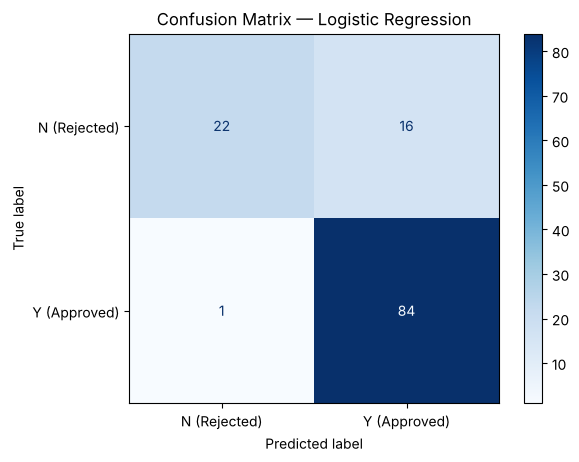

In [9]:
best = results_df.index[0]
print('Best model:', best)
cm = confusion_matrix(y_test, preds[best])
ConfusionMatrixDisplay(cm, display_labels=['N (Rejected)', 'Y (Approved)']).plot(cmap='Blues')
plt.title(f'Confusion Matrix — {best}')
plt.show()

## 8. Justification
**Logistic Regression** is the selected model. It has the highest Accuracy (0.862), Precision (0.840), F1 (0.908) and ROC-AUC (0.849) of the four models, so it separates approved from rejected applicants best across all thresholds.
All four models reach a similar Recall (~0.98), so the deciding factors are precision and AUC, and Logistic Regression leads on both. It is also simple and interpretable, which matters for explaining credit decisions. The confusion matrix shows its main weakness: it misclassifies some rejected loans as approved, largely because the model leans heavily on `Credit_History`.